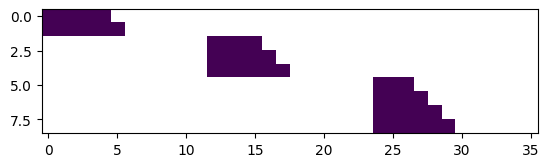

In [1]:
import xformers.ops as xops
import matplotlib.pyplot as plt
import torch

mask = xops.fmha.attn_bias.BlockDiagonalCausalWithOffsetPaddedKeysMask.from_seqlens(
  q_seqlen=[2, 3, 4],
  kv_padding=12,
  kv_seqlen=[6, 6, 6],
)
m = mask.materialize(shape=(1, 1, 9, 36))
m = m[0, 0]
plt.imshow(m)

torch.Size([1, 9, 1, 32])
True
0.0


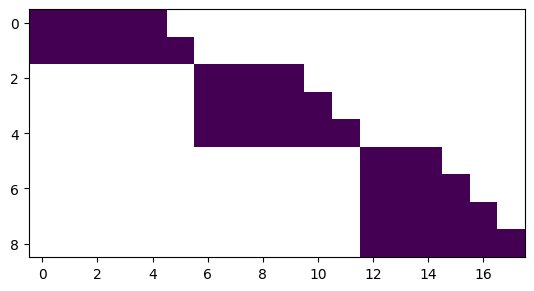

In [2]:
q = torch.randn(1, 9, 1, 32).cuda()
k = torch.randn(1, 36, 1, 32).cuda()
v = torch.randn(1, 36, 1, 32).cuda()
out_1 = xops.fmha.memory_efficient_attention(q, k, v, attn_bias=mask)
print(out_1.shape)

non_padded_k = torch.split(k, [12, 12, 12], dim=1)
non_padded_k = torch.cat([k[:, :s] for (k, s) in zip(non_padded_k, [6, 6, 6])], dim=1)
non_padded_v = torch.split(v, [12, 12, 12], dim=1)
non_padded_v = torch.cat([v[:, :s] for (v, s) in zip(non_padded_v, [6, 6, 6])], dim=1)

mask = xops.fmha.attn_bias.BlockDiagonalCausalFromBottomRightMask.from_seqlens(
  q_seqlen=[2, 3, 4],
  kv_seqlen=[6, 6, 6],
)
m = mask.materialize(shape=(1, 1, 9, 18))
m = m[0, 0]
plt.imshow(m)


out_2 = xops.fmha.memory_efficient_attention(q, non_padded_k, non_padded_v, attn_bias=mask)
print(torch.allclose(out_1, out_2))
print((out_1 - out_2).abs().max().item())